
AVERAGE UX RESPONSE PER QUESTION

           Q1    Q2   Q3    Q4    Q5    Q6    Q7    Q8    Q9   Q10   Q11   Q12
group                                                                         
control  4.46  4.23  4.0  3.23  4.46  4.62  4.77  4.77  4.69  4.31  4.85  4.77
test     4.18  4.18  4.0  2.91  4.18  3.91  4.73  4.82  3.82  3.91  4.27  4.18


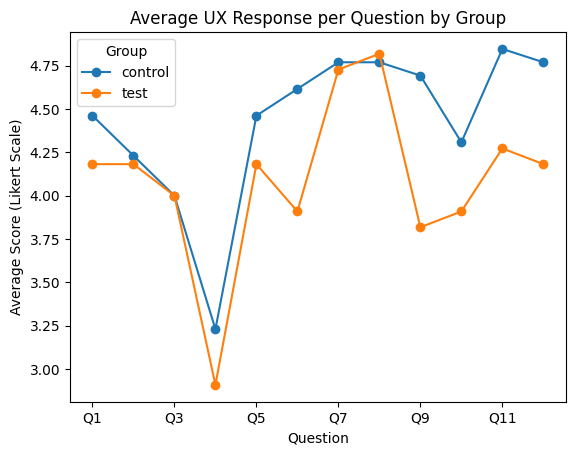

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

participants = pd.read_csv("participants.csv")
ux = pd.read_csv("ux_survey_submissions.csv")

ux_df = ux.merge(
    participants[["participant_id", "group"]],
    on="participant_id",
    how="left"
)

def parse_answers(x):
    if pd.isna(x):
        return []

    cleaned = str(x).strip().replace("{", "").replace("}", "")

    try:
        return [int(i.strip()) for i in cleaned.split(",") if i.strip() != ""]
    except:
        return []

ux_df["parsed_answers"] = ux_df["answers"].apply(parse_answers)

for i in range(12):
    ux_df[f"Q{i+1}"] = ux_df["parsed_answers"].apply(
        lambda x: x[i] if i < len(x) else np.nan
    )

question_cols = [f"Q{i+1}" for i in range(12)]

group_means = ux_df.groupby("group")[question_cols].mean()

print("\n==============================")
print("AVERAGE UX RESPONSE PER QUESTION")
print("==============================\n")

print(group_means.round(2))

group_means.T.plot(marker="o")

plt.title("Average UX Response per Question by Group")
plt.xlabel("Question")
plt.ylabel("Average Score (Likert Scale)")

plt.xticks(rotation=0)
plt.legend(title="Group")

plt.show()